<a href="https://colab.research.google.com/github/rahulSaxena28/-ARpirahul/blob/main/shortcut_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import torch
import torchvision
import os

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU mode: use a small smoke test first")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [4]:
!git clone https://github.com/rgeirhos/shortcut-perspective.git
%cd /content/shortcut-perspective
!git log -1 --oneline
!git ls-files
!find code -maxdepth 3 -type f

Cloning into 'shortcut-perspective'...
remote: Enumerating objects: 85, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 85 (delta 1), reused 6 (delta 1), pack-reused 78 (from 1)
Receiving objects: 100% (85/85), 22.60 MiB | 15.49 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/shortcut-perspective
89c0e9b (HEAD -> master, origin/master, origin/HEAD) Merge branch 'master' of github.com:rgeirhos/shortcut-perspective
README.md
code/bunny.npy
code/cow.npy
code/shortcut_toy_exp.py
figures/generalisation.png
figures/taxonomy.png
figures/teaser_figure.pdf
figures/toy_figure.png
code/bunny.npy
code/shortcut_toy_exp.py
code/cow.npy


In [5]:
from pathlib import Path

for path in Path("code").rglob("*.py"):
    print(f"\n{'=' * 70}\nFILE: {path}\n{'=' * 70}")
    print(path.read_text()[:12000])


FILE: code/shortcut_toy_exp.py
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.utils.data as utils
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
import sys
import IPython
import time
import IPython.display as display


# Dataset specification
n = 1000
dim = 1
std = 10.0
# Train specification
epochs = 100
lr = 0.0001
bs = 100
log_interval = 10

from torchvision.utils import make_grid as make_grid
#from PIL import Image
import requests
from io import BytesIO
import cv2
from resizeimage import resizeimage

bunny = np.load('bunny.npy')
bunny = bunny
#bunny = Image.open('/content/bunny04.png')#BytesIO(response.content))
#bunny = np.uint8(np.array(bunny))
#bunny = bunny//255
#bunny = np.abs(bunny-1)
#bunny = np.pad(bunny,((54,54),(34,34)),mode='constant')

cow = np.load('cow.npy')
cow = cow
#cow = Image.open('/content/cow1.png') #BytesIO(response.content))
#cow = np.uint8(np.array(cow))
#cow = cv2.resize(cow, (90,100),

In [6]:

%%writefile /content/shortcut-perspective/cifar10_shortcut.py
import csv
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.datasets import CIFAR10


# ---------------- Configuration ----------------
SEEDS = [42, 123, 2026, 7, 99]
DATA_ROOT = "/content/data"
RESULT_DIR = Path("/content/shortcut-perspective/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = int(os.getenv("EPOCHS", "10"))
BATCH_SIZE = int(os.getenv("BATCH_SIZE", "128"))
TRAIN_LIMIT = int(os.getenv("TRAIN_LIMIT", "0"))  # 0 = full training split
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


# Ten deliberately distinct shortcut colors in RGB [0, 1].
COLORS = torch.tensor([
    [1, 0, 0], [0, 1, 0], [0, 0, 1], [1, 1, 0],
    [1, 0, 1], [0, 1, 1], [1, .5, 0], [.5, 0, 1],
    [0, .5, 1], [.5, 1, 0],
], dtype=torch.float32)

MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)


class ShortcutCIFAR(Dataset):
    """
    mode='train'/'iid': patch matches the true class.
    mode='clean': no patch.
    mode='conflict': patch indicates the next class.
    """
    def __init__(self, base, indices, mode):
        self.base = base
        self.indices = list(indices)
        self.mode = mode

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        image, label = self.base[self.indices[i]]
        image = torch.from_numpy(np.array(image)).permute(2, 0, 1)
        image = image.float() / 255.0

        if self.mode != "clean":
            shortcut_label = label
            if self.mode == "conflict":
                shortcut_label = (label + 1) % 10

            # 5x5 patch in the top-right corner.
            color = COLORS[shortcut_label].view(3, 1, 1)
            image[:, 0:5, 27:32] = color

        image = (image - MEAN) / STD
        return image, label


class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x).argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
    return 100.0 * correct / total


def train_one_seed(seed, train_base, test_base, train_indices,
                   val_indices, test_indices):
    set_seed(seed)
    start = time.time()

    train_ds = ShortcutCIFAR(train_base, train_indices, "train")
    val_ds = ShortcutCIFAR(train_base, val_indices, "iid")
    iid_ds = ShortcutCIFAR(test_base, test_indices, "iid")
    clean_ds = ShortcutCIFAR(test_base, test_indices, "clean")
    conflict_ds = ShortcutCIFAR(test_base, test_indices, "conflict")

    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
        generator=generator
    )

    def eval_loader(ds):
        return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS,
                          pin_memory=torch.cuda.is_available())

    val_loader = eval_loader(val_ds)
    iid_loader = eval_loader(iid_ds)
    clean_loader = eval_loader(clean_ds)
    conflict_loader = eval_loader(conflict_ds)

    model = SmallCNN().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss, seen = 0.0, 0

        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * y.size(0)
            seen += y.size(0)

        val_acc = accuracy(model, val_loader)
        print(
            f"seed={seed} epoch={epoch}/{EPOCHS} "
            f"loss={running_loss/seen:.4f} val_acc={val_acc:.2f}%"
        )

    result = {
        "seed": seed,
        "epochs": EPOCHS,
        "train_examples": len(train_ds),
        "val_accuracy": accuracy(model, val_loader),
        "iid_accuracy": accuracy(model, iid_loader),
        "clean_accuracy": accuracy(model, clean_loader),
        "conflict_accuracy": accuracy(model, conflict_loader),
        "clean_gap_pp": (
            accuracy(model, iid_loader) - accuracy(model, clean_loader)
        ),
        "conflict_gap_pp": (
            accuracy(model, iid_loader) - accuracy(model, conflict_loader)
        ),
        "seconds": round(time.time() - start, 1),
    }

    torch.save(model.state_dict(), RESULT_DIR / f"model_seed_{seed}.pt")
    return result


def main():
    # Download CIFAR-10 only once.
    train_base = CIFAR10(DATA_ROOT, train=True, download=True)
    test_base = CIFAR10(DATA_ROOT, train=False, download=True)

    # Fixed split across runs; seeds vary initialization and shuffle.
    split_rng = np.random.default_rng(2026)
    indices = split_rng.permutation(len(train_base))
    train_indices = indices[5000:]
    val_indices = indices[:5000]

    if TRAIN_LIMIT > 0:
        train_indices = train_indices[:TRAIN_LIMIT]

    test_indices = range(len(test_base))
    all_results = []

    csv_path = RESULT_DIR / "results.csv"

    for seed in SEEDS:
        print(f"\n===== STARTING SEED {seed} =====")
        result = train_one_seed(
            seed, train_base, test_base,
            train_indices, val_indices, test_indices
        )
        all_results.append(result)

        # Save after every run, so completed runs are not lost.
        with open(csv_path, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=all_results[0].keys())
            writer.writeheader()
            writer.writerows(all_results)

        print("Saved:", csv_path)
        print(result)

    # Mean and standard deviation across the five runs.
    metric_names = [
        "val_accuracy", "iid_accuracy", "clean_accuracy",
        "conflict_accuracy", "clean_gap_pp", "conflict_gap_pp"
    ]
    summary_path = RESULT_DIR / "summary.csv"
    with open(summary_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["metric", "mean", "std_sample"])
        for metric in metric_names:
            values = np.array([r[metric] for r in all_results])
            writer.writerow([
                metric, round(values.mean(), 4),
                round(values.std(ddof=1), 4)
            ])

    print("\nAll runs complete.")
    print("Detailed results:", csv_path)
    print("Summary:", summary_path)


if __name__ == "__main__":
    main()


Writing /content/shortcut-perspective/cifar10_shortcut.py


In [7]:
SEEDS = [
    int(s) for s in os.getenv(
        "SEEDS", "42,123,2026,7,99"
    ).split(",")
]

In [8]:
!EPOCHS=1 TRAIN_LIMIT=1000 SEEDS=42 \
python /content/shortcut-perspective/cifar10_shortcut.py

Device: cuda
100% 170M/170M [20:24<00:00, 139kB/s]

===== STARTING SEED 42 =====
seed=42 epoch=1/1 loss=2.2786 val_acc=18.36%
Saved: /content/shortcut-perspective/results/results.csv
{'seed': 42, 'epochs': 1, 'train_examples': 1000, 'val_accuracy': 18.36, 'iid_accuracy': 16.96, 'clean_accuracy': 16.16, 'conflict_accuracy': 15.62, 'clean_gap_pp': 0.8000000000000007, 'conflict_gap_pp': 1.3400000000000016, 'seconds': 15.3}

===== STARTING SEED 123 =====
seed=123 epoch=1/1 loss=2.2841 val_acc=17.00%
Saved: /content/shortcut-perspective/results/results.csv
{'seed': 123, 'epochs': 1, 'train_examples': 1000, 'val_accuracy': 17.0, 'iid_accuracy': 16.81, 'clean_accuracy': 16.21, 'conflict_accuracy': 15.57, 'clean_gap_pp': 0.5999999999999979, 'conflict_gap_pp': 1.2399999999999984, 'seconds': 12.9}

===== STARTING SEED 2026 =====
seed=2026 epoch=1/1 loss=2.2946 val_acc=14.24%
Saved: /content/shortcut-perspective/results/results.csv
{'seed': 2026, 'epochs': 1, 'train_examples': 1000, 'val_accuracy

In [1]:
import torch
print(torch.cuda.is_available())

True


In [9]:
!EPOCHS=10 TRAIN_LIMIT=0 SEEDS=42,123,2026,7,99 \
python /content/shortcut-perspective/cifar10_shortcut.py

Device: cuda

===== STARTING SEED 42 =====
seed=42 epoch=1/10 loss=0.7797 val_acc=97.92%
seed=42 epoch=2/10 loss=0.0440 val_acc=99.70%
seed=42 epoch=3/10 loss=0.0160 val_acc=99.90%
seed=42 epoch=4/10 loss=0.0086 val_acc=99.88%
seed=42 epoch=5/10 loss=0.0053 val_acc=99.98%
seed=42 epoch=6/10 loss=0.0041 val_acc=99.98%
seed=42 epoch=7/10 loss=0.0022 val_acc=99.98%
seed=42 epoch=8/10 loss=0.0017 val_acc=99.90%
seed=42 epoch=9/10 loss=0.0013 val_acc=99.64%
seed=42 epoch=10/10 loss=0.0006 val_acc=99.98%
Saved: /content/shortcut-perspective/results/results.csv
{'seed': 42, 'epochs': 10, 'train_examples': 45000, 'val_accuracy': 99.98, 'iid_accuracy': 99.97, 'clean_accuracy': 13.37, 'conflict_accuracy': 0.01, 'clean_gap_pp': 86.6, 'conflict_gap_pp': 99.96, 'seconds': 95.6}

===== STARTING SEED 123 =====
seed=123 epoch=1/10 loss=0.8543 val_acc=94.80%
seed=123 epoch=2/10 loss=0.1010 val_acc=99.28%
seed=123 epoch=3/10 loss=0.0310 val_acc=97.80%
seed=123 epoch=4/10 loss=0.0170 val_acc=99.90%
seed=

,seed,epochs,train_examples,val_accuracy,iid_accuracy,clean_accuracy,conflict_accuracy,clean_gap_pp,conflict_gap_pp,seconds
0,42,10,45000,99.98,99.97,13.37,0.01,86.60,99.96,95.6
1,123,10,45000,99.76,99.79,10.38,0.00,89.41,99.79,95.9
2,2026,10,45000,99.86,99.88,10.61,0.00,89.27,99.88,97.7
3,7,10,45000,99.96,99.98,15.34,0.00,84.64,99.98,95.4
4,99,10,45000,100.00,99.92,13.02,0.00,86.90,99.92,96.0


,metric,mean,std_sample
0,val_accuracy,99.91,0.10
1,iid_accuracy,99.91,0.08
2,clean_accuracy,12.54,2.07
3,conflict_accuracy,0.00,0.00
4,clean_gap_pp,87.36,2.00
5,conflict_gap_pp,99.91,0.08


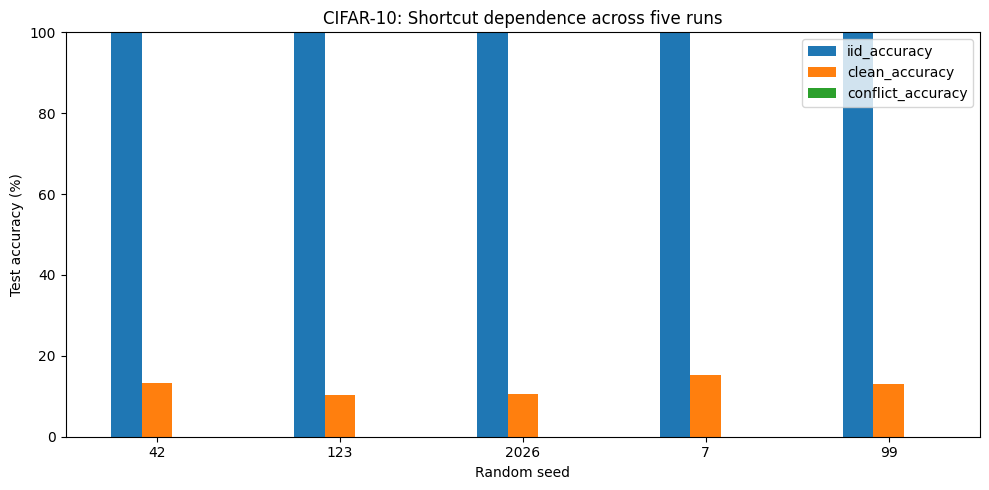

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

results_path = "/content/shortcut-perspective/results/results.csv"
summary_path = "/content/shortcut-perspective/results/summary.csv"

df = pd.read_csv(results_path)
summary = pd.read_csv(summary_path)

display(df.round(2))
display(summary.round(2))

metrics = [
    "iid_accuracy",
    "clean_accuracy",
    "conflict_accuracy"
]

df.set_index("seed")[metrics].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 100)
)
plt.ylabel("Test accuracy (%)")
plt.xlabel("Random seed")
plt.title("CIFAR-10: Shortcut dependence across five runs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p /content/drive/MyDrive/shortcut_cifar10_results
!cp -r /content/shortcut-perspective/results/* \
    /content/drive/MyDrive/shortcut_cifar10_results/

Mounted at /content/drive
